In [4]:
import numpy as np 
import matplotlib.pyplot as plt
import os

In [5]:
from pathlib import Path
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR
print(NOTEBOOK_DIR)
while not (PROJECT_ROOT / "python").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent
    print(PROJECT_ROOT)
os.chdir(PROJECT_ROOT)



/Users/valentinmercier/Desktop/2025/recherche/gnn_modulus_test/Aube
/Users/valentinmercier/Desktop/2025/recherche/gnn_modulus_test


In [7]:
def _is_float_token(token):
    try:
        float(token)
        return True
    except ValueError:
        return False
    
def load_liq_table(liq_path):
    header = None
    rows = []

    with open(liq_path, "r", encoding="utf-8", errors="ignore") as f:
        for raw_line in f:
            line = raw_line.strip()
            if not line or line.startswith("#"):
                continue

            parts = line.split()
            if not all(_is_float_token(token) for token in parts):
                if header is None:
                    header = parts
                continue

            rows.append([float(token) for token in parts])

    if not rows:
        raise ValueError(f"No numeric hydrograph data found in {liq_path}")

    data = np.asarray(rows, dtype=np.float32)
    if data.ndim != 2 or data.shape[1] < 2:
        raise ValueError(f"Hydrograph {liq_path} must contain at least time and one value column.")

    if header is None or len(header) != data.shape[1]:
        header = ["T"] + [f"COL_{idx}" for idx in range(1, data.shape[1])]

    order = np.argsort(data[:, 0])
    return data[order], header


def load_liq_q_series(liq_path):
    data, header = load_liq_table(liq_path)
    time_seconds = data[:, 0]

    q_indices = [
        idx
        for idx, name in enumerate(header[1:], start=1)
        if name.upper().startswith("Q")
    ]
    if not q_indices:
        q_indices = [data.shape[1] - 1]

    q_values = data[:, q_indices].astype(np.float32)
    q_labels = [header[idx] for idx in q_indices]

    if q_values.ndim == 1:
        q_values = q_values[:, None]

    return time_seconds, q_values, q_labels

In [63]:
test_path = "./data/T1_Q2_V1.liq"

In [64]:
time_seconds, q_values, q_labels = load_liq_q_series(test_path)

In [65]:
print(time_seconds.shape)
print(q_values.shape)
print(q_labels)

(382,)
(382, 3)
['Q(1)', 'Q(2)', 'Q(3)']


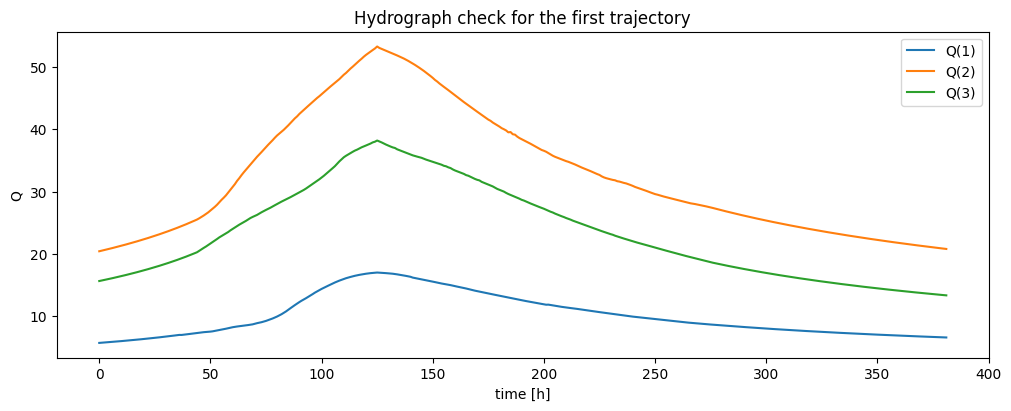

In [66]:
time_hours = time_seconds * 7200 / 3600.0

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for source_id, label in enumerate(q_labels):
    ax.plot(time_seconds / 3600.0, q_values[:, source_id], label=label)

ax.set_xlabel("time [h]")
ax.set_ylabel("Q")
ax.set_title("Hydrograph check for the first trajectory")
ax.legend(loc="best")
plt.show()

In [ ]:
test_paths = ["./data/T1_Q2_V1.liq",
              "./data/T1_Q5_V1.liq",
              "./data/T1_Q10_V1.liq",
              "./data/T1_Q30_V1.liq",
              "./data/T1_Q50_V1.liq",
              "./data/T1_Q100_V1.liq",
              "./data/Q_janvier2018_V3.liq"
              ]

def compute_kc(array_of_q):
    peak_index = np.argmax(array_of_q)
    #calculer la daily mean discharge maximisée contenant le peak 
    #creer les fenetres 
    span = list(range(peak_index-23,peak_index+24))
    sub_span = []
    for i in range(len(span) - 24 + 1):
        sub_span.append(span[i: i + 24])
    #print(sub_span)
    mean_of_subspan = np.mean(array_of_q[sub_span],axis=1)
    #diviser le max par ça 
    return array_of_q[peak_index]/np.max(mean_of_subspan)

time_seconds, q_values, q_labels = load_liq_q_series(test_paths[0])
floods_per_Q = {}
for Q in q_labels :
    floods_per_Q[Q] = []

for test_path in test_paths :
    print(test_path)
    time_seconds, q_values, q_labels = load_liq_q_series(test_path)
    for i,Q in enumerate(q_labels) :
        floods_per_Q[Q].append(q_values[:,i])
        
for Q in q_labels :
    print(max(map(np.max,floods_per_Q[Q])))
    print(min(map(np.max,floods_per_Q[Q])))

./data/T1_Q2_V1.liq
./data/T1_Q5_V1.liq
./data/T1_Q10_V1.liq
./data/T1_Q30_V1.liq
./data/T1_Q50_V1.liq
./data/T1_Q100_V1.liq
./data/Q_janvier2018_V3.liq
60.0
17.0
159.2982
53.304436
130.28468
38.202103


In [113]:
for i in range(len(floods_per_Q['Q(3)'])): 
    print(compute_kc(floods_per_Q['Q(3)'][i]))

1.0254431
1.0254431
1.025443
1.0254432
1.0254431
1.0254431
1.0273405


In [111]:
a = []
a.append([np.zeros(4)])
print(a)

[[array([0., 0., 0., 0.])]]


In [114]:
RETURN_PERIODS = [2, 5, 10, 30, 50, 100]

LIQ_FILES = {
    period: Path(f"data/T1_Q{period}_V1.liq")
    for period in RETURN_PERIODS
}

TRAIN_SCENARIOS = {
    "M1_T5_T10_T30": (5, 10, 30),
    "M2_T10_T30_T5": (10, 30, 5),
    "M3_T30_T5_T10": (30, 5, 10),
    "H1_T30_T50_T100": (30, 50, 100),
    "H2_T50_T100_T30": (50, 100, 30),
    "H3_T100_T30_T50": (100, 30, 50),
}

TEST_SCENARIOS = {
    "TEST_M_T5_T30_T10": (5, 30, 10),
    "TEST_H_T50_T30_T100": (50, 30, 100),
}

OUTPUT_DIR = Path("Aube/generated_hydrographs_T1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

template, header = load_liq_table(LIQ_FILES[2])
q_columns = [header.index(f"Q({index})") for index in range(1, 4)]
sl_column = header.index("SL(4)")

time_seconds = template[:, 0]
sl_values = template[:, sl_column]

normalized_profiles = []
peaks_by_period = {}

for period, path in LIQ_FILES.items():
    data, _ = load_liq_table(path)
    q_values = data[:, q_columns]
    peaks = q_values.max(axis=0)

    peaks_by_period[period] = peaks
    normalized_profiles.append(q_values / peaks)

representative_profile = np.mean(normalized_profiles, axis=0)
profile_spread = np.ptp(np.stack(normalized_profiles), axis=0).max()

print("maximum normalized profile spread:", profile_spread)


def write_liq(path, time_seconds, q_values, sl_values):
    with path.open("w", encoding="utf-8") as file:
        file.write("# Fichier des frontières liquides transitoires\n")
        file.write("# Hydrogramme multisource synthétique\n")
        file.write("T Q(1) Q(2) Q(3) SL(4)\n")
        file.write("s m2/s m2/s m2/s m\n")

        for time, q, sl in zip(time_seconds, q_values, sl_values):
            file.write(
                f"{time:.0f} {q[0]:.9f} {q[1]:.9f} "
                f"{q[2]:.9f} {sl:.9f}\n"
            )


generated = {}

for split, scenarios in {
    "train": TRAIN_SCENARIOS,
    "test": TEST_SCENARIOS,
}.items():
    for name, periods in scenarios.items():
        target_peaks = np.array([
            peaks_by_period[period][source_id]
            for source_id, period in enumerate(periods)
        ])

        q_values = representative_profile * target_peaks
        output_path = OUTPUT_DIR / f"{name}.liq"

        write_liq(output_path, time_seconds, q_values, sl_values)
        generated[name] = q_values

        print(
            split,
            output_path,
            "periods:",
            periods,
            "peaks:",
            np.round(q_values.max(axis=0), 3),
            "Kc:",
            np.round(
                [compute_kc(q_values[:, index]) for index in range(3)],
                3,
            ),
        )

maximum normalized profile spread: 1.7881393e-07
train Aube/generated_hydrographs_T1/M1_T5_T10_T30.liq periods: (5, 10, 30) peaks: [24.    84.666 89.316] Kc: [1.013 1.024 1.025]
train Aube/generated_hydrographs_T1/M2_T10_T30_T5.liq periods: (10, 30, 5) peaks: [ 28.    111.075  55.025] Kc: [1.013 1.024 1.025]
train Aube/generated_hydrographs_T1/M3_T30_T5_T10.liq periods: (30, 5, 10) peaks: [41.    72.173 66.163] Kc: [1.013 1.024 1.025]
train Aube/generated_hydrographs_T1/H1_T30_T50_T100.liq periods: (30, 50, 100) peaks: [ 41.    129.264 130.285] Kc: [1.013 1.024 1.025]
train Aube/generated_hydrographs_T1/H2_T50_T100_T30.liq periods: (50, 100, 30) peaks: [ 48.    159.298  89.316] Kc: [1.013 1.024 1.025]
train Aube/generated_hydrographs_T1/H3_T100_T30_T50.liq periods: (100, 30, 50) peaks: [ 60.    111.075 104.915] Kc: [1.013 1.024 1.025]
test Aube/generated_hydrographs_T1/TEST_M_T5_T30_T10.liq periods: (5, 30, 10) peaks: [ 24.    111.075  66.163] Kc: [1.013 1.024 1.025]
test Aube/generate

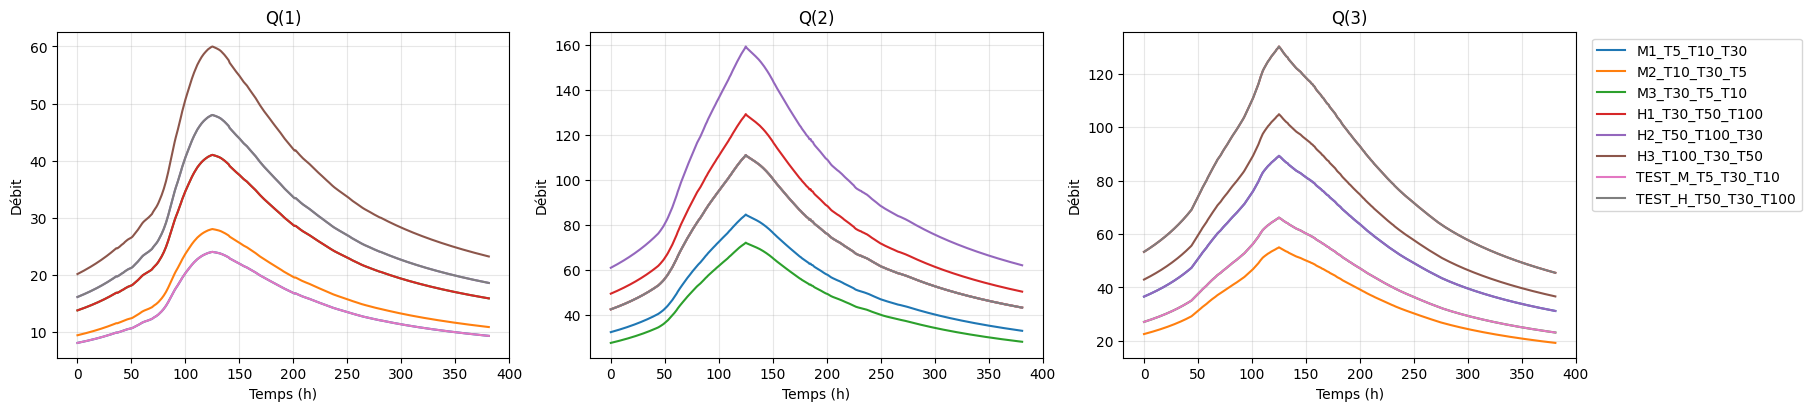

In [115]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)

for name, q_values in generated.items():
    for source_id, ax in enumerate(axes):
        ax.plot(
            time_seconds / 3600,
            q_values[:, source_id],
            label=name,
        )

for source_id, ax in enumerate(axes):
    ax.set_title(f"Q({source_id + 1})")
    ax.set_xlabel("Temps (h)")
    ax.set_ylabel("Débit")
    ax.grid(alpha=0.3)

axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()